In [1]:
# 02 · Feature engineering, chronological split & baselines
# AI-use disclosure: developed with the help of Claude Code (Anthropic). AI-assisted: code structure, the
# data-processing and model code (src/ and this notebook) and plotting code. Done by the student
# (B. G. M. Prabuddhi): choice of problem and data, data and modelling decisions, reviewing and running the
# code, interpreting the results. Details: AI_DISCLOSURE.md | Written analysis: reports/ANALYSIS.md

import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

from src import data, features as F, evaluate as E
dengue = data.load_dengue_clean()
weather = data.load_weather_weekly()
print("weather available:", weather is not None)

weather available: True


In [2]:
panel = F.build_panel(dengue, weather)
num_feats = F.numeric_features(with_weather=weather is not None)
print("panel shape:", panel.shape, "| numeric features:", len(num_feats), "| + district one-hot")
panel[panel.district == "Colombo"][["origin_date", "target_date", "target", "cases_lag1", "cases_lag2",
                                    "rolling_mean_4", "rain_mm_lag1", "rain_mm_lag8", "week", "week_sin"]].iloc[700:705]

panel shape: (26753, 43) | numeric features: 35 | + district one-hot


,origin_date,target_date,target,cases_lag1,cases_lag2,rolling_mean_4,rain_mm_lag1,rain_mm_lag8,week,week_sin
4816,2020-05-23,2020-05-30,81.0,80.0,67.0,44.25,77.2,67.9,22,0.472823
4817,2020-05-30,2020-06-06,62.0,81.0,80.0,63.00,21.5,36.4,23,0.363552
4818,2020-06-06,2020-06-13,70.0,62.0,81.0,72.50,124.7,28.6,24,0.249016
4819,2020-06-13,2020-06-20,58.0,70.0,62.0,73.25,43.7,21.9,25,0.130874
4820,2020-06-20,2020-06-27,50.0,58.0,70.0,67.75,55.5,29.4,26,0.010837


In [3]:
ok, n = True, 0
for d, g in panel.groupby("district"):
    tgt, nxt_lag1 = g.target.values[:-1], g.cases_lag1.values[1:]
    real = ~np.isnan(tgt)            # where week t+1 was a missing report, lag1 holds the carried-forward value
    ok &= np.allclose(tgt[real], nxt_lag1[real]); n += real.sum()
print(f"target(t) == cases_lag1(t+1) for every district ({n:,} reported weeks checked):", ok)
print("target_date always after origin_date:", bool((panel.target_date > panel.origin_date).all()))

target(t) == cases_lag1(t+1) for every district (26,157 reported weeks checked): True
target_date always after origin_date: True


In [4]:
splits = F.split_panel(panel)
pd.DataFrame({k: {"rows": len(v), "first target week": v.target_date.min().date(), "last target week": v.target_date.max().date(),
                  "mean target": round(v.target.mean(), 1) if v.target.notna().any() else None}
              for k, v in splits.items()}).T

,rows,first target week,last target week,mean target
train,19731,2007-02-24,2021-12-25,30.1
val,1328,2022-01-01,2022-12-24,23.9
test,4854,2022-12-31,2026-08-24,52.9
excluded_recent,52,2026-08-31,2026-09-07,25.3
forecast,26,2026-09-14,2026-09-14,None


In [5]:
dropped_target = panel[(panel.history_weeks > F.WARMUP_WEEKS) & panel.target.isna() & (panel.origin_date < panel.origin_date.max())]
print("rows dropped because the target week was a missing report:", len(dropped_target))
print("rows dropped as warm-up (first 8 weeks of each region):", int((panel.history_weeks <= F.WARMUP_WEEKS).sum()))
print("\nNaN counts in TRAIN features (handled by the imputer, not dropped):")
print(splits["train"][num_feats].isna().sum().loc[lambda s: s > 0].to_string())

rows dropped because the target week was a missing report: 554
rows dropped as warm-up (first 8 weeks of each region): 208

NaN counts in TRAIN features (handled by the imputer, not dropped):
rolling_mean_4     6
rolling_std_4      6
rolling_mean_8    12


In [6]:
import joblib
prep = F.make_preprocessor(num_feats)
X_train = prep.fit_transform(splits["train"][F.all_features(weather is not None)])
names = prep.get_feature_names_out()
print("transformed training matrix:", X_train.shape)
print("was-missing indicator columns:", [n for n in names if n.startswith("missingindicator")])
config.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(prep, config.MODELS_DIR / "preprocessor.joblib", compress=3)
print("saved models/preprocessor.joblib")

transformed training matrix: (19731, 64)
was-missing indicator columns: ['missingindicator_rolling_mean_4', 'missingindicator_rolling_std_4', 'missingindicator_rolling_mean_8']
saved models/preprocessor.joblib


In [7]:
rows = []
for split_name in ["val", "test"]:
    s = splits[split_name]
    for name, col in [(E.NAIVE_NAME, "naive_pred"), ("Seasonal naive (last year)", "seasonal_pred")]:
        rows.append({"split": split_name, "model": name, **E.regression_metrics(s.target, s[col])})
base = pd.DataFrame(rows).round(3)
base     # recorded in models/results.csv in section 7, once the risk thresholds are saved

,split,model,MAE,RMSE,R2,sMAPE
0,val,Naive (last week),11.547,20.485,0.284,61.218
1,val,Seasonal naive (last year),20.114,35.138,-1.106,106.863
2,test,Naive (last week),14.949,37.586,0.867,46.210
3,test,Seasonal naive (last year),37.753,95.695,0.140,79.931


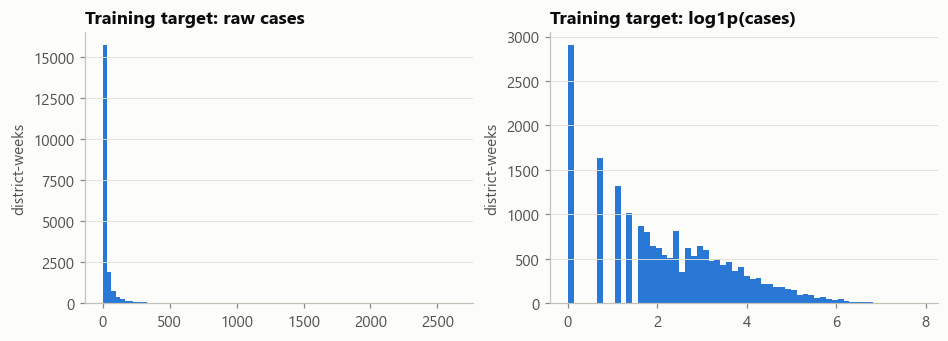

skewness raw = 10.80  |  skewness log1p = 0.34


In [8]:
y = splits["train"].target
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(y, bins=80, color=viz.SERIES[0]); axes[0].set_title("Training target: raw cases")
axes[1].hist(np.log1p(y), bins=60, color=viz.SERIES[0]); axes[1].set_title("Training target: log1p(cases)")
for ax in axes: ax.set_ylabel("district-weeks")
viz.save(fig, "fe_target_distribution"); plt.show()
print(f"skewness raw = {y.skew():.2f}  |  skewness log1p = {np.log1p(y).skew():.2f}")

In [9]:
import time
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

feats = F.all_features(weather is not None)
tr, va = splits["train"], splits["val"]
candidates = {
    "RandomForest": lambda: RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=3,
                                                  n_jobs=-1, random_state=config.RANDOM_STATE),
    "LightGBM": lambda: LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                      random_state=config.RANDOM_STATE, verbose=-1),
}
rows = []
for name, make in candidates.items():
    for use_log in [False, True]:
        pipe = F.make_model_pipeline(make(), num_feats, use_log=use_log)
        t0 = time.time(); pipe.fit(tr[feats], tr.target)
        m = E.regression_metrics(va.target, pipe.predict(va[feats]))
        rows.append({"model": name, "target": "log1p" if use_log else "raw", **m, "fit_s": round(time.time() - t0, 1)})
tt = pd.DataFrame(rows)
naive_val_mae = E.regression_metrics(va.target, va.naive_pred)["MAE"]
tt["MAE_vs_naive_pct"] = E.improvement(tt.MAE, naive_val_mae)
display(tt.round(3))

mean_mae = tt.groupby("target").MAE.mean()
USE_LOG = bool(mean_mae["log1p"] < mean_mae["raw"])
print("mean validation MAE by target:", mean_mae.round(3).to_dict())
print("DECISION -> train all models on", "log1p(cases)" if USE_LOG else "raw cases")

,model,target,MAE,RMSE,R2,sMAPE,fit_s,MAE_vs_naive_pct
0,RandomForest,raw,10.665,17.945,0.451,56.511,44.4,7.638
1,RandomForest,log1p,10.327,17.375,0.485,58.255,39.8,10.571
2,LightGBM,raw,10.698,18.114,0.440,57.461,4.4,7.356
3,LightGBM,log1p,10.533,17.733,0.464,59.620,2.2,8.785


mean validation MAE by target: {'log1p': 10.43, 'raw': 10.682}
DECISION -> train all models on log1p(cases)


In [10]:
thr = F.compute_risk_thresholds(dengue)
thr_df = pd.DataFrame(thr).T.round(1).sort_values("high", ascending=False)
display(thr_df.head(8))

for split_name in ["val", "test"]:
    s = splits[split_name]
    lv = [F.risk_level(c, d, thr) for c, d in zip(s.target, s.district)]
    print(f"{split_name}: actual risk-level mix", pd.Series(lv).value_counts(normalize=True).mul(100).round(1).to_dict())

,medium,high
Colombo,110.0,217.0
Gampaha,45.0,93.0
Kandy,29.0,60.0
Kalutara,25.0,46.0
Kurunegala,23.0,46.0
Ratnapura,20.0,42.0
Jaffna,13.0,39.8
Batticaloa,11.0,34.0


val: actual risk-level mix {'High': 37.5, 'Low': 32.5, 'Medium': 30.0}
test: actual risk-level mix {'High': 55.2, 'Medium': 30.7, 'Low': 14.2}


In [11]:
panel.to_csv(F.FEATURES_CSV, index=False)
splits["forecast"].to_csv(F.FORECAST_CSV, index=False)
cfg = {
    "use_log_target": USE_LOG,
    "target_transform_validation_mae": mean_mae.round(4).to_dict(),
    "with_weather": weather is not None,
    "numeric_features": num_feats,
    "categorical_features": F.CATEGORICAL_FEATURES,
    "weather_lags": config.WEATHER_LAGS,
    "risk_thresholds": thr,
    "train_target_range": [str(splits["train"].target_date.min().date()), str(splits["train"].target_date.max().date())],
    "val_target_range": [str(splits["val"].target_date.min().date()), str(splits["val"].target_date.max().date())],
    "test_target_range": [str(splits["test"].target_date.min().date()), str(splits["test"].target_date.max().date())],
    "excluded_recent_weeks": sorted(str(d.date()) for d in splits["excluded_recent"].target_date.unique()),
    "forecast_target_week": str(splits["forecast"].target_date.iloc[0].date()),
    "districts": sorted(panel.district.unique()),
}
F.save_feature_config(cfg)
print("saved", F.FEATURES_CSV.name, F.FORECAST_CSV.name, F.FEATURE_CONFIG_JSON.name)
{k: v for k, v in cfg.items() if k not in ("numeric_features", "risk_thresholds", "districts")}

saved features.csv forecast_features.csv feature_config.json


{'use_log_target': True,
 'target_transform_validation_mae': {'log1p': 10.4299, 'raw': 10.6818},
 'with_weather': True,
 'categorical_features': ['district'],
 'weather_lags': [1, 2, 3, 4, 5, 6, 7, 8],
 'train_target_range': ['2007-02-24', '2021-12-25'],
 'val_target_range': ['2022-01-01', '2022-12-24'],
 'test_target_range': ['2022-12-31', '2026-08-24'],
 'excluded_recent_weeks': ['2026-08-31', '2026-09-07'],
 'forecast_target_week': '2026-09-14'}

In [12]:
te, va = splits["test"], splits["val"]
E.record_result(E.NAIVE_NAME, "Baseline", te, te.naive_pred, val=va, val_pred=va.naive_pred)
E.record_result("Seasonal naive (last year)", "Baseline", te, te.seasonal_pred, val=va, val_pred=va.seasonal_pred)
print(f"test weeks classed as outbreak weeks: {E.outbreak_mask(te).mean():.1%}")
E.results_table().round(3)

test weeks classed as outbreak weeks: 55.2%


,model,family,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,RMSE_vs_naive_pct,MAE_normal,MAE_outbreak,val_MAE,train_time_s
0,Naive (last week),Baseline,14.949,37.586,0.867,46.210,0.000,0.000,7.432,21.062,11.547,0.00
1,Seasonal naive (last year),Baseline,37.753,95.695,0.140,79.931,-152.540,-154.600,17.630,54.118,20.114,0.00
2,Extra Trees,Bagging,14.506,39.089,0.856,43.813,2.963,-3.997,6.199,21.262,10.340,4.98
3,Random Forest,Bagging,14.520,37.472,0.868,44.349,2.874,0.304,6.073,21.389,10.393,8.49
4,Bagging (Decision Trees),Bagging,14.701,38.281,0.862,44.465,1.659,-1.848,6.031,21.752,10.449,6.69
5,Gradient Boosting,Boosting,15.447,43.010,0.826,43.936,-3.327,-14.429,5.894,23.216,10.430,4.09
6,CatBoost,Boosting,15.714,44.105,0.817,44.693,-5.115,-17.343,6.139,23.501,10.562,0.60
7,AdaBoost,Boosting,16.021,47.361,0.789,45.136,-7.169,-26.006,6.327,23.904,10.484,1.74
8,XGBoost,Boosting,16.508,51.886,0.747,44.382,-10.425,-38.045,5.926,25.113,10.442,0.30
9,LightGBM,Boosting,18.593,50.949,0.756,46.669,-24.376,-35.553,5.983,28.849,10.576,0.48
